# 17 — Results (draft of Section 5)

Every result below is read from the cached campaign files; nothing is simulated here. Prose is written as the paper's Results section. Pending campaigns (exp2, exp3, the second engine) are marked.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from mvlse import fit_surrogate

sys.path.insert(0, str(Path.cwd().parent))
import common
import config

RES = Path.cwd().parent / "results" / "exp1_heading"
run = json.loads((RES / "campaign" / "run.json").read_text())
bracket = json.loads((RES / "bracket" / "run.json").read_text())
train = [json.loads(l) for l in (RES / "campaign" / "store.jsonl").read_text().splitlines() if l.strip()]
space = config.space_of(config.EXPERIMENTS["exp1_heading"]["space"])
TAU, N = config.TAU, config.N_ENCOUNTERS
w = space.encode([r["point"] for r in train])
y = np.array([r["y"] for r in train])
model = fit_surrogate(config.LSE["method"], space, w, y, correlation=config.LSE["correlation"],
                      rng=np.random.default_rng(config.SEED), n_starts=12)
levels = {n: space.variable(n).levels for n in space.discrete_names}
kt = lambda v: f"{v / config.KT:.0f} kt"
TWO = ListedColormap(["tab:red", "tab:green"])                      # outside, inside the level set

# Predictions on a grid: 41 x 41 (reception, range) per category, 37 headings.
N_P, N_R, N_PSI = 41, 41, 37
pu, ru, su = np.linspace(0, 1, N_P), np.linspace(0, 1, N_R), np.linspace(0, 1, N_PSI)
phys = {n: space.variable(n).from_unit(a) for n, a in zip(space.continuous_names, (pu, ru, su))}
G = np.stack(np.meshgrid(pu, ru, su, indexing="ij"), -1).reshape(-1, 3)
MU, S = {}, {}
for cat in space.categories:
    m, s = model.predict(np.column_stack([G, np.tile(np.array(cat, float), (len(G), 1))]))
    MU[cat], S[cat] = m.reshape(N_P, N_R, N_PSI), s.reshape(N_P, N_R, N_PSI)
print(f"exp1: {len(y)} samples, {run['outcome']['n_initial']} initial; {len(MU)} categories predicted")

exp1: 250 samples, 36 initial; 36 categories predicted


## 5.1 Simulation setup and bracket check

Exp. 1 ran 250 samples: 36 initial samples, one per category, and 214 acquired with the straddle, each response estimated from $10^5$ encounters. The campaign took 6.0 h on 100 parallel workers.

A bracket check first confirmed that the design space contains the boundary. With the best CNS combination (reception probability 1, surveillance range 15 km, 3 m position and 1 m/s velocity accuracy) at a 90° crossing, no LoS occurred in $10^5$ encounters in any speed class ($P(\mathrm{LoS}) < 3\times10^{-5}$). With the worst combination (0.1, 300 m, 92.6 m, 10 m/s) at 170°, $P(\mathrm{LoS})$ was 0.94 to 1. The samples split evenly, 125 acceptable and 125 not, and 44 of them (18%) had no LoS.

In [2]:
# Bracket check and campaign facts.
rows = [{"speed class": kt(c["point"]["speed"]), "heading [deg]": c["point"]["dpsi"],
         "CNS": "best" if c["point"]["p_reception"] == 1.0 else "worst",
         "P(LoS)": common.show_p(c["y"]), "acceptable": c["acceptable"]} for c in bracket["outcome"]["corners"]]
display(pd.DataFrame(rows))
zero = np.sum(y <= np.log10(0.5 / (N + 1)) + 1e-9)
print(f"campaign: {len(y)} samples at {N:.0e} encounters each, {run['outcome']['seconds'] / 3600:.1f} h on "
      f"{run['shared']['N_JOBS']} workers; {zero} samples ({zero / len(y):.0%}) with no LoS; "
      f"{np.sum(y <= TAU)} acceptable, {np.sum(y > TAU)} not")

,speed class,heading [deg],CNS,P(LoS),acceptable
0,20 kt,90.0,best,P(LoS) = 0 observed (0 losses in 100000; < 3.0...,True
1,20 kt,170.0,worst,"P(LoS) = 9.36e-01 95% CI [9.3e-01, 9.4e-01]",False
2,40 kt,90.0,best,P(LoS) = 0 observed (0 losses in 100000; < 3.0...,True
3,40 kt,170.0,worst,"P(LoS) = 1.00e+00 95% CI [1.0e+00, 1.0e+00]",False
4,60 kt,90.0,best,P(LoS) = 0 observed (0 losses in 100000; < 3.0...,True
5,60 kt,170.0,worst,"P(LoS) = 1.00e+00 95% CI [1.0e+00, 1.0e+00]",False


campaign: 250 samples at 1e+05 encounters each, 6.0 h on 100 workers; 44 samples (18%) with no LoS; 125 acceptable, 125 not


## 5.2 Two regimes in relative heading

There is no single worst heading: it is set by whichever CNS parameter is weak (Fig. R1).

- **Poor reception: the shallow encounter is worst.** At reception probability 0.2 and 15 km range, $P(\mathrm{LoS})$ peaks at 2° in every speed class at 1 and 3 m/s.
- **Short range: the head-on encounter is worst.** At 0.7 km range it peaks at 180°. At 40 and 60 kt, $P(\mathrm{LoS})$ grows from about $10^{-5}$ at 2° to about $4\times10^{-3}$ at 180°.
- **Good CNS: the risk is lowest at crossing angles.** The prediction is U-shaped over the heading, with its minimum between 60° and 120°.

Both regimes are consistent with the closure rate.
- **Shallow conflicts close slowly.** They last long enough for missed messages and state errors to accumulate.
- **Head-on conflicts close at twice the cruise speed.** They leave little time between detection and closest approach.

The share of the (reception, range) plane in which 2° is the worst heading falls with speed: 71–73% for 20 kt (1 and 3 m/s), 47–53% for 40 kt and 36–42% for 60 kt. 180° takes over as the closure rate grows. Only at 10 m/s, where no combination is acceptable, does the worst heading lie inside the range (55–85% of the plane).

Because the worst heading moves between the two ends, the requirement is read as the worst case over the heading (Section 5.4), and Exp. 2 conditions on both ends, 2° and 180°.

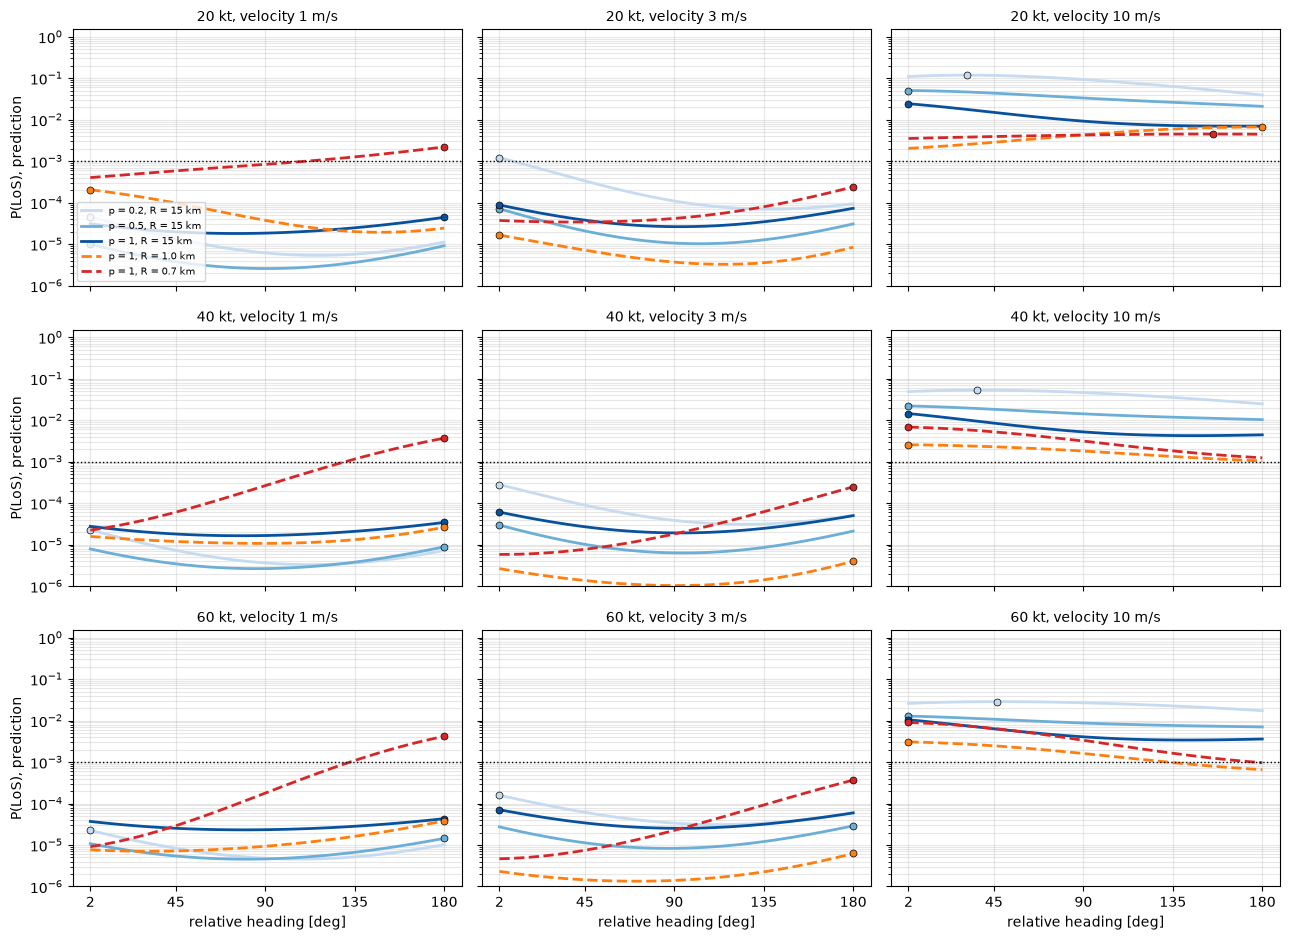

,speed,velocity [m/s],worst at 2 deg,worst at 180 deg,worst in between
0,20 kt,1.0,0.71,0.29,0.00
1,20 kt,3.0,0.73,0.20,0.08
2,20 kt,10.0,0.10,0.05,0.85
3,40 kt,1.0,0.47,0.49,0.05
4,40 kt,3.0,0.53,0.39,0.08
5,40 kt,10.0,0.32,0.05,0.63
6,60 kt,1.0,0.36,0.56,0.08
7,60 kt,3.0,0.42,0.48,0.10
8,60 kt,10.0,0.41,0.04,0.55


In [3]:
# P(LoS) against relative heading (prediction), position accuracy 10 m.
POS = 1
ip = lambda v: int(np.argmin(np.abs(phys["p_reception"] - v)))
ir = lambda km: int(np.argmin(np.abs(phys["max_range_m"] / 1e3 - km)))
CURVES = [(f"p = {v:g}, R = 15 km", ip(v), N_R - 1, c, "-") for v, c in ((0.2, "#c6dbef"), (0.5, "#6baed6"), (1.0, "#08519c"))] + \
         [(f"p = 1, R = {phys['max_range_m'][ir(km)] / 1e3:.1f} km", N_P - 1, ir(km), c, "--")
          for km, c in ((1.0, "tab:orange"), (0.5, "tab:red"))]
fig, axes = plt.subplots(3, 3, figsize=(13, 9.5), sharex=True, sharey=True)
worst = []
for k, spd in enumerate(levels["speed"]):
    for j, vel in enumerate(levels["vel_ci95"]):
        ax = axes[k, j]
        for label, a, b, color, ls in CURVES:
            p = 10 ** MU[POS, j, k][a, b, :]
            ax.plot(phys["dpsi"], p, color=color, ls=ls, lw=2, label=label)
            iw = int(np.argmax(p)); ax.plot(phys["dpsi"][iw], p[iw], "o", color=color, ms=5, mec="k", mew=0.5)
        ax.axhline(1e-3, color="k", lw=1, ls=":"); ax.set_yscale("log"); ax.set_ylim(1e-6, 1.5)
        ax.set_xticks([2, 45, 90, 135, 180]); ax.grid(alpha=0.3, which="both")
        ax.set_title(f"{kt(spd)}, velocity {vel:g} m/s", fontsize=10)
        if k == 2: ax.set_xlabel("relative heading [deg]")
        if j == 0: ax.set_ylabel("P(LoS), prediction")
axes[0, 0].legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.savefig("results/R_plos_vs_heading.png", dpi=130); plt.show()

# Where the worst heading lies, over the whole (reception, range) grid, per class (all positions).
for k, spd in enumerate(levels["speed"]):
    for j, vel in enumerate(levels["vel_ci95"]):
        iw = np.concatenate([MU[i, j, k].argmax(-1).ravel() for i in range(4)])
        worst.append({"speed": kt(spd), "velocity [m/s]": vel,
                      "worst at 2 deg": np.mean(iw == 0), "worst at 180 deg": np.mean(iw == N_PSI - 1),
                      "worst in between": np.mean((iw > 0) & (iw < N_PSI - 1))})
display(pd.DataFrame(worst).round(2))

## 5.3 The requirement over the CNS variables

**Velocity accuracy decides the requirement.** At 10 m/s no combination of reception, range and position accuracy is acceptable, in any speed class. At 1 m/s, 92–97% of the reception–range plane is acceptable, and at 3 m/s, 76–91% (Fig. R2, prediction, worst case over the heading).

**Position accuracy barely matters.** Across the four classes, from 3 m to 92.6 m, the acceptable share changes by at most 0.05.

What remains is set by the other two variables:
- **Range:** a floor of about 1–1.5 km in every class, rising to about 4 km at low reception for 60 kt at 1 m/s.
- **Reception:** at 3 m/s, a floor of about 0.15–0.35, highest for 20 kt.

**At 250 samples, the modelling uncertainty matters more than the prediction.** Read at the prediction + 1.96 × the modelling uncertainty, the acceptable share drops:

| velocity accuracy | 20 kt | 40 kt | 60 kt |
|---|---|---|---|
| 1 m/s | 0.22–0.43 | 0.42–0.61 | 0.34–0.48 |
| 3 m/s | 0.05–0.13 | 0.30–0.47 | 0.26–0.42 |

The fragmented dashed contours in Fig. R2 are this uncertainty. The hold-out check (Section 5.6) shows it is wider than necessary, so the conservative reading is safe, but stricter than the data require.

The boundary check (Section 5.6) shows that these floors are too lenient: designs on the predicted boundary mostly measure above $10^{-3}$.

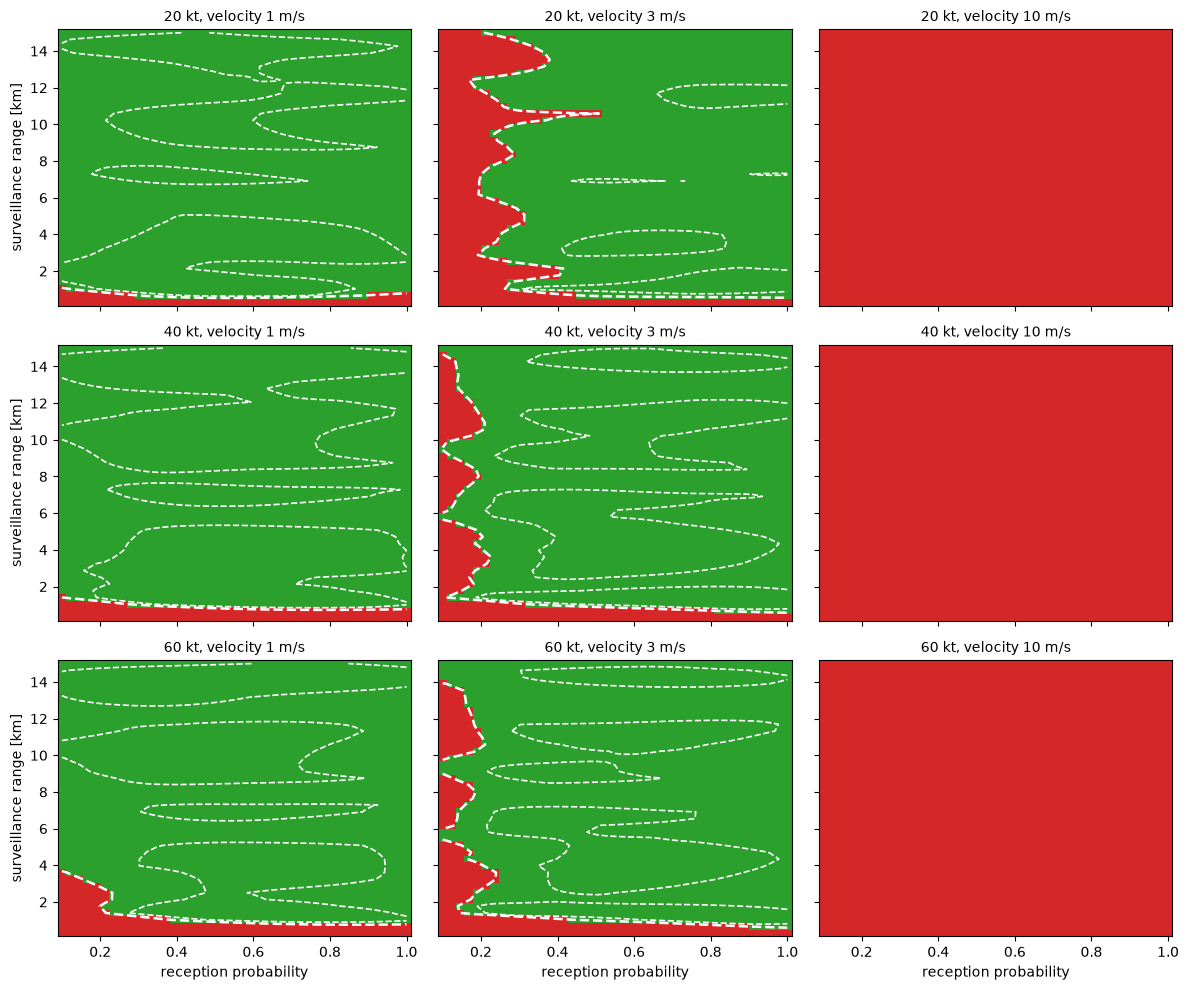

position [m]          3.0   10.0  30.0  92.6
speed velocity [m/s]                        
20 kt 1.0             0.97  0.97  0.97  0.97
      3.0             0.76  0.77  0.81  0.78
      10.0            0.00  0.00  0.00  0.00
40 kt 1.0             0.94  0.95  0.95  0.95
      3.0             0.86  0.88  0.91  0.88
      10.0            0.00  0.00  0.00  0.00
60 kt 1.0             0.93  0.92  0.94  0.94
      3.0             0.87  0.88  0.91  0.90
      10.0            0.00  0.00  0.00  0.00

prediction       prediction + 1.96 s      
                            min   max                 min   max
speed velocity [m/s]                                           
20 kt 1.0                  0.97  0.97                0.22  0.43
      3.0                  0.76  0.81                0.05  0.13
      10.0                 0.00  0.00                0.00  0.00
40 kt 1.0                  0.94  0.95                0.42  0.61
      3.0                  0.86  0.91                0.30  0.47
      10.0                 0.00  0.00                0.00  0.00
60 kt 1.0                  0.92  0.94                0.34  0.48
      3.0                  0.87  0.91                0.26  0.42
      10.0                 0.00  0.00                0.00  0.00

In [4]:
# The requirement: acceptable where P(LoS) <= 1e-3 at every heading (worst case over the heading),
# reception-range plane, position accuracy 10 m. White: boundary from the prediction; dashed: from
# the prediction + 1.96 x modelling uncertainty.
POS = 1
fig, axes = plt.subplots(3, 3, figsize=(12, 10), sharex=True, sharey=True)
PR, RR = np.meshgrid(phys["p_reception"], phys["max_range_m"] / 1e3, indexing="ij")
for k, spd in enumerate(levels["speed"]):
    for j, vel in enumerate(levels["vel_ci95"]):
        ax = axes[k, j]
        mu_w = MU[POS, j, k].max(-1)
        up_w = (MU[POS, j, k] + 1.96 * S[POS, j, k]).max(-1)
        ax.pcolormesh(PR, RR, (mu_w <= TAU).astype(float), cmap=TWO, vmin=0, vmax=1, shading="auto")
        ax.contour(PR, RR, mu_w, levels=[TAU], colors="white", linewidths=1.8)
        ax.contour(PR, RR, up_w, levels=[TAU], colors="white", linewidths=1.2, linestyles="--")
        ax.set_title(f"{kt(spd)}, velocity {vel:g} m/s", fontsize=10)
        if k == 2: ax.set_xlabel("reception probability")
        if j == 0: ax.set_ylabel("surveillance range [km]")
plt.tight_layout(); plt.savefig("results/R_requirement_maps.png", dpi=130); plt.show()

share = []
for (ipos, ivel, k), mu in MU.items():
    share.append({"speed": kt(levels["speed"][k]), "velocity [m/s]": levels["vel_ci95"][ivel],
                  "position [m]": levels["pos_ci95"][ipos],
                  "prediction": np.mean(mu.max(-1) <= TAU),
                  "prediction + 1.96 s": np.mean((mu + 1.96 * S[ipos, ivel, k]).max(-1) <= TAU)})
share = pd.DataFrame(share)
display(share.pivot_table(index=["speed", "velocity [m/s]"], columns="position [m]", values="prediction").round(2))
display(share.groupby(["speed", "velocity [m/s]"])[["prediction", "prediction + 1.96 s"]].agg(["min", "max"]).round(2))

## 5.4 The definition over the heading

The requirement is read as the worst case over the heading. Replacing it with an average over the heading changes the result only at 3 m/s:

| speed class | worst case | uniform average | closing-speed weighted |
|---|---|---|---|
| 20 kt | 0.78 | 0.87 | 0.89 |
| 40 kt | 0.88 | 0.93 | 0.93 |
| 60 kt | 0.89 | 0.92 | 0.93 |

(Acceptable share of the reception–range plane at 3 m/s.)

At 1 and 10 m/s, all three definitions agree. The velocity requirement therefore does not depend on how the heading is weighted. Only the reception and range floors at 3 m/s do.

In [5]:
# The requirement under three definitions over the heading (acceptable share of the reception-range
# plane, prediction, averaged over position classes). Averages are over probabilities.
psi = phys["dpsi"]
WEIGHTS = {"uniform average": np.ones_like(psi) / len(psi),
           "closing-speed weighted": np.sin(np.radians(psi) / 2) / np.sin(np.radians(psi) / 2).sum()}
rows = []
for k, spd in enumerate(levels["speed"]):
    for j, vel in enumerate(levels["vel_ci95"]):
        r = {"speed": kt(spd), "velocity [m/s]": vel}
        r["worst case"] = np.mean([np.mean(MU[i, j, k].max(-1) <= TAU) for i in range(4)])
        for name, wt in WEIGHTS.items():
            r[name] = np.mean([np.mean(np.log10((10 ** MU[i, j, k] * wt).sum(-1)) <= TAU) for i in range(4)])
        rows.append(r)
pd.DataFrame(rows).round(2)

,speed,velocity [m/s],worst case,uniform average,closing-speed weighted
0,20 kt,1.0,0.97,0.97,0.97
1,20 kt,3.0,0.78,0.87,0.89
2,20 kt,10.0,0.00,0.00,0.00
3,40 kt,1.0,0.95,0.96,0.96
4,40 kt,3.0,0.88,0.93,0.93
5,40 kt,10.0,0.00,0.00,0.00
6,60 kt,1.0,0.93,0.95,0.95
7,60 kt,3.0,0.89,0.93,0.92
8,60 kt,10.0,0.00,0.00,0.00


## 5.5 Correlations between levels

The hypersphere decomposition estimates one correlation matrix per discrete variable (Fig. R3). The matrices explain the results above:

- **Position accuracy:** the levels are correlated at 0.89–0.99. The surrogate model treats the four classes as nearly the same response, which is the insensitivity of Section 5.3.
- **Velocity accuracy:** the 10 m/s level is negatively correlated with 1 m/s (−0.27), and only weakly correlated with 3 m/s (0.35). The coarsest class behaves differently, not as more of the same error. A correlation function that cannot represent a negative correlation between levels can at best treat these two as uncorrelated (Section 4.2). The negative value is therefore the case for the hypersphere decomposition on this data.
- **Speed class:** 40 and 60 kt, both fixed-wing, are correlated at 0.97, while the 20 kt multirotor is less correlated with them (0.85 and 0.72).

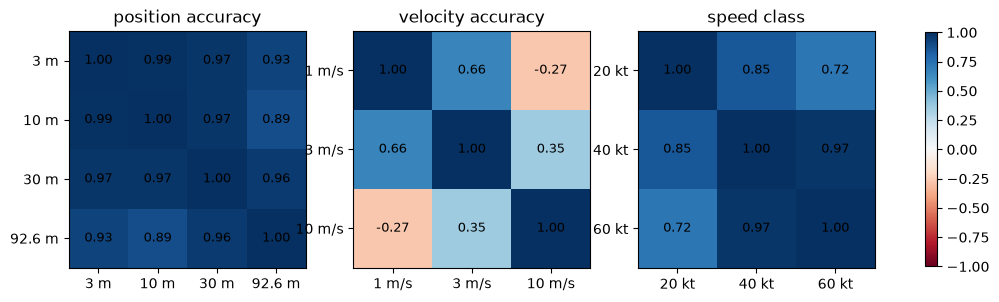

In [6]:
# Correlations between the levels of each discrete variable (hypersphere decomposition).
lc = model.level_correlations()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, name, unit in zip(axes, ("pos_ci95", "vel_ci95", "speed"), ("m", "m/s", "")):
    labels = [kt(v) if name == "speed" else f"{v:g} {unit}" for v in levels[name]]
    m = np.asarray(lc[name])
    im = ax.imshow(m, vmin=-1, vmax=1, cmap="RdBu")
    for (a, b), v in np.ndenumerate(m):
        ax.text(b, a, f"{v:.2f}", ha="center", va="center", fontsize=9)
    ax.set_xticks(range(len(labels)), labels); ax.set_yticks(range(len(labels)), labels)
    ax.set_title({"pos_ci95": "position accuracy", "vel_ci95": "velocity accuracy", "speed": "speed class"}[name])
fig.colorbar(im, ax=axes, shrink=0.8)
plt.savefig("results/R_level_correlations.png", dpi=130); plt.show()

## 5.6 Reliability of the fitted boundary

**(a) The active learning process.** The run ended on its limit of 250 samples, not resolved:
- **Max straddle:** it never fell below zero, ending at +1.48.
- **Ambiguous points:** the share of points whose interval still contains $10^{-3}$ rose from about 3% after the initial samples to 10–30% (Fig. R4).
- **Why it rose:** the surrogate model fitted to the 36 initial samples is overconfident. As samples reveal the structure of the response, the re-estimated hyperparameters widen its modelling uncertainty.

A run that ends this way has not shown that the boundary is resolved. Its accuracy is therefore checked directly against new samples.

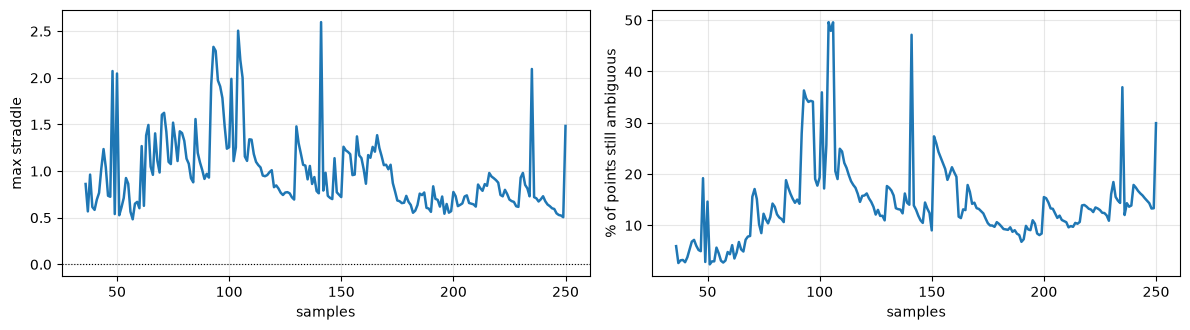

final max straddle +1.48; ambiguous 30%; stop: budget (250 evaluations)


In [7]:
# (a) The active learning process: max straddle and share of points whose interval contains 1e-3.
rounds = pd.DataFrame(run["outcome"]["rounds"])
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.4))
a.plot(rounds.n_evaluations, rounds.max_straddle, lw=1.8); a.axhline(0, color="k", lw=0.8, ls=":")
a.set_xlabel("samples"); a.set_ylabel("max straddle"); a.grid(alpha=0.3)
b.plot(rounds.n_evaluations, 100 * rounds.ambiguous_fraction, lw=1.8)
b.set_xlabel("samples"); b.set_ylabel("% of points still ambiguous"); b.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("results/R_convergence.png", dpi=130); plt.show()
print(f"final max straddle {run['outcome']['final_max_straddle']:+.2f}; ambiguous "
      f"{run['outcome']['final_ambiguous_fraction']:.0%}; stop: {run['outcome']['stop_reason']}")

**(b1) Hold-out samples.** 108 unmapped points (3 per category, uniform in reception, range and heading) were simulated with $10^5$ encounters each. Their encounters are independent of the campaign's.

- **Side of $10^{-3}$:** the prediction placed all 108 on the correct side. This says little about the boundary itself: only 2 of them were measured within half a decade of $10^{-3}$, because the response jumps across the threshold rather than crossing it gently.
- **Accuracy:** over the 60 points with LoS, the prediction is typically within a factor of 1.9 of the measured value (median), with an RMS error of 0.46 decades.
- **Uncertainty:** the modelling uncertainty is honest and cautious. Normalised errors $z = (y - \hat y)/\sqrt{s^2 + s_{MC}^2}$ have mean −0.16 and standard deviation 0.70 (ideal 0 and 1), and all 60 points lie inside the 95% interval.
- **No-LoS points:** of the 48 with no LoS, 44 are predicted below the $3/N$ bound, and the other 4 above it, on the safe side.

108 hold-out points, 60 with LoS, 48 without
side of 1e-3 correct: 100%; within 0.5 decade of 1e-3: 2 points
error of the prediction: median factor 1.9, RMS 0.46 decades
z = (measured - prediction) / sqrt(s^2 + se^2): mean -0.16, sd 0.70; inside the 95% interval 100%


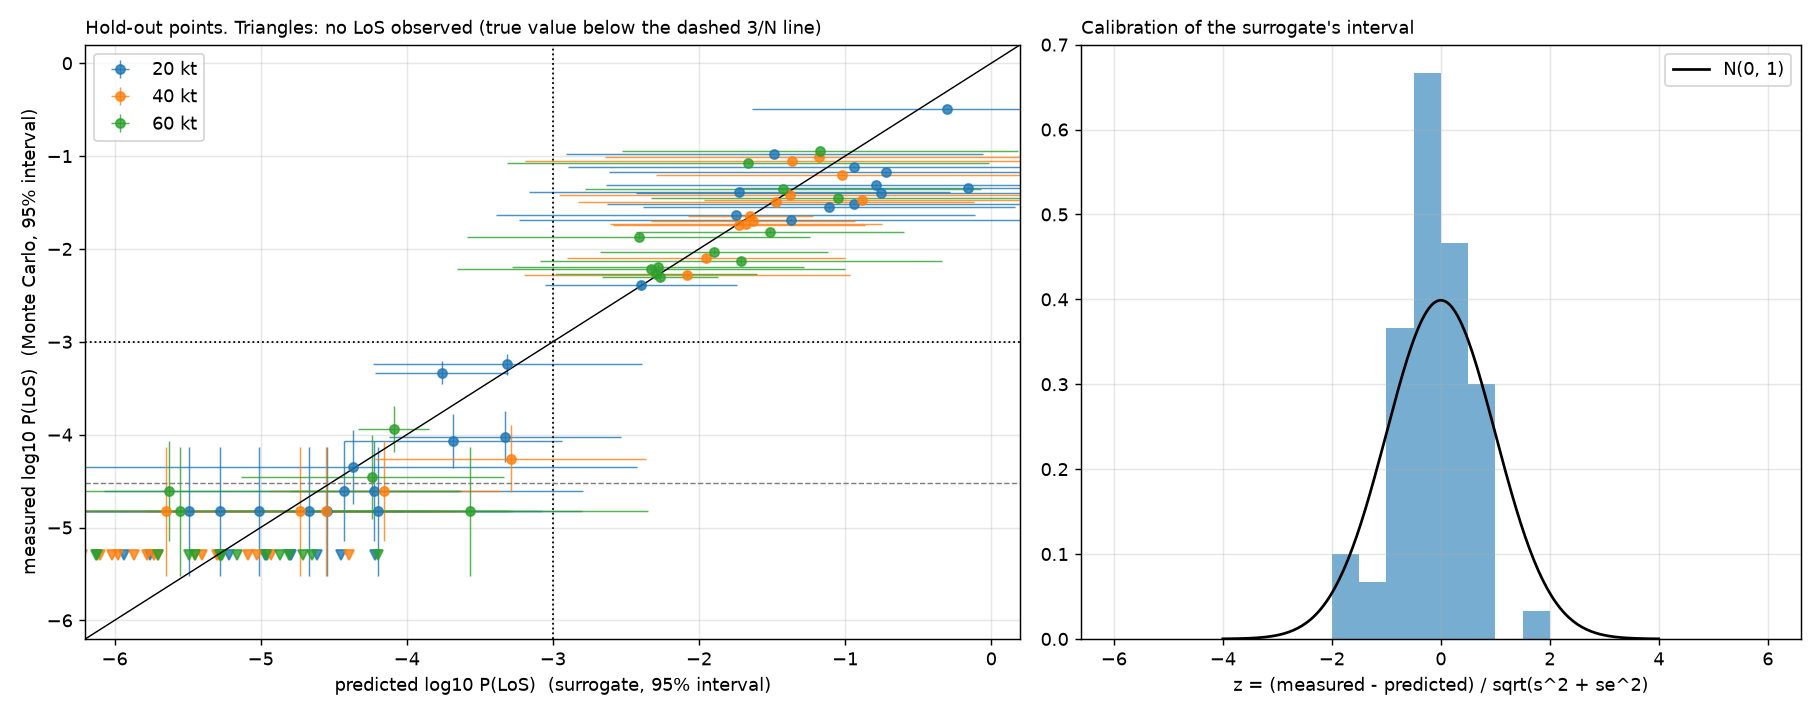

In [8]:
# (b1) Hold-out samples (notebook 15): 108 unmapped points, fresh Monte Carlo on independent encounters.
ho = pd.read_csv("results/exp1_holdout.csv")
nz = ho[~ho.zero]
print(f"{len(ho)} hold-out points, {len(nz)} with LoS, {int(ho.zero.sum())} without")
print(f"side of 1e-3 correct: {ho.class_ok.mean():.0%}; within 0.5 decade of 1e-3: {int(ho.near_tau.sum())} points")
print(f"error of the prediction: median factor {10 ** np.median(np.abs(nz.y - nz.mu)):.1f}, "
      f"RMS {np.sqrt(np.mean((nz.y - nz.mu) ** 2)):.2f} decades")
print(f"z = (measured - prediction) / sqrt(s^2 + se^2): mean {nz.z.mean():+.2f}, sd {nz.z.std():.2f}; "
      f"inside the 95% interval {nz.inside95.mean():.0%}")
from IPython.display import Image
display(Image("results/exp1_holdout.png", width=900))

**(b2) Boundary check.** 30 designs whose predicted worst case over the heading equals $10^{-3}$ (at most two per category) were simulated with $10^6$ encounters at their predicted worst heading, and with $10^5$ at the other end of the heading range. Their encounters are independent of the campaign's.

**The surrogate model is least accurate where the requirement is decided.**
- **Spread of the measured values:** from no LoS to $3\times10^{-2}$, a median factor of 4 from the prediction.
- **Interval:** only 16 of 30 lie inside the 95% interval. The hold-out showed cautious intervals overall; on the boundary they are overconfident.

**The error is systematic, by heading.**
- **2°:** where 2° was predicted worst, 13 of 14 designs measure above $10^{-3}$ (median factor 3.6, up to 20).
- **180°:** where 180° was predicted worst, 7 of 8 measure below.
- **Wrong end:** in 8 of 30 the other end is clearly worse than the predicted worst heading.

$P(\mathrm{LoS})$ rises towards the shallow end faster than the surrogate model, fitted to the 49 samples between 2° and 20°, can follow.

**The requirement of Section 5.3 is therefore too lenient.** 23 of the 30 boundary designs exceed $10^{-3}$ at one of the two ends, so the true acceptable region is smaller than predicted. The conclusions that do not depend on the boundary's exact position stand: 10 m/s is never acceptable, and position accuracy barely matters. The exact reception and range floors do not.

,speed_kt,vel,pos,p,R_km,worst dpsi,predicted,measured,meas 95% lo,meas 95% hi,predicted acceptable,measured acceptable,other end measured
0,20,3.0,10.0,0.3700,10.2225,2.00000,0.00100,0.00290,0.00280,0.00301,True,False,0.00001
1,20,3.0,30.0,0.2575,12.7950,2.00000,0.00100,0.00633,0.00617,0.00648,False,False,0.00007
2,40,3.0,3.0,0.1900,13.5300,2.00000,0.00100,0.00362,0.00350,0.00374,True,False,0.00028
3,20,3.0,30.0,0.4600,0.6675,180.00000,0.00100,0.00003,0.00002,0.00004,True,True,0.00160
4,20,3.0,92.6,0.3700,1.0350,2.00000,0.00100,0.00250,0.00240,0.00260,False,False,0.00005
5,40,3.0,30.0,0.1225,5.0775,2.00000,0.00100,0.01334,0.01312,0.01357,False,False,0.00085
6,20,3.0,92.6,0.5275,0.6675,180.00000,0.00100,0.00051,0.00047,0.00056,True,True,0.00142
7,60,3.0,10.0,0.1675,8.3850,66.27778,0.00100,0.00018,0.00015,0.00020,False,True,0.00062
8,20,3.0,10.0,0.5050,10.5900,2.00000,0.00100,0.00136,0.00129,0.00143,False,False,0.00003
9,60,3.0,30.0,0.1675,10.2225,180.00000,0.00100,0.00019,0.00016,0.00022,True,True,0.00037


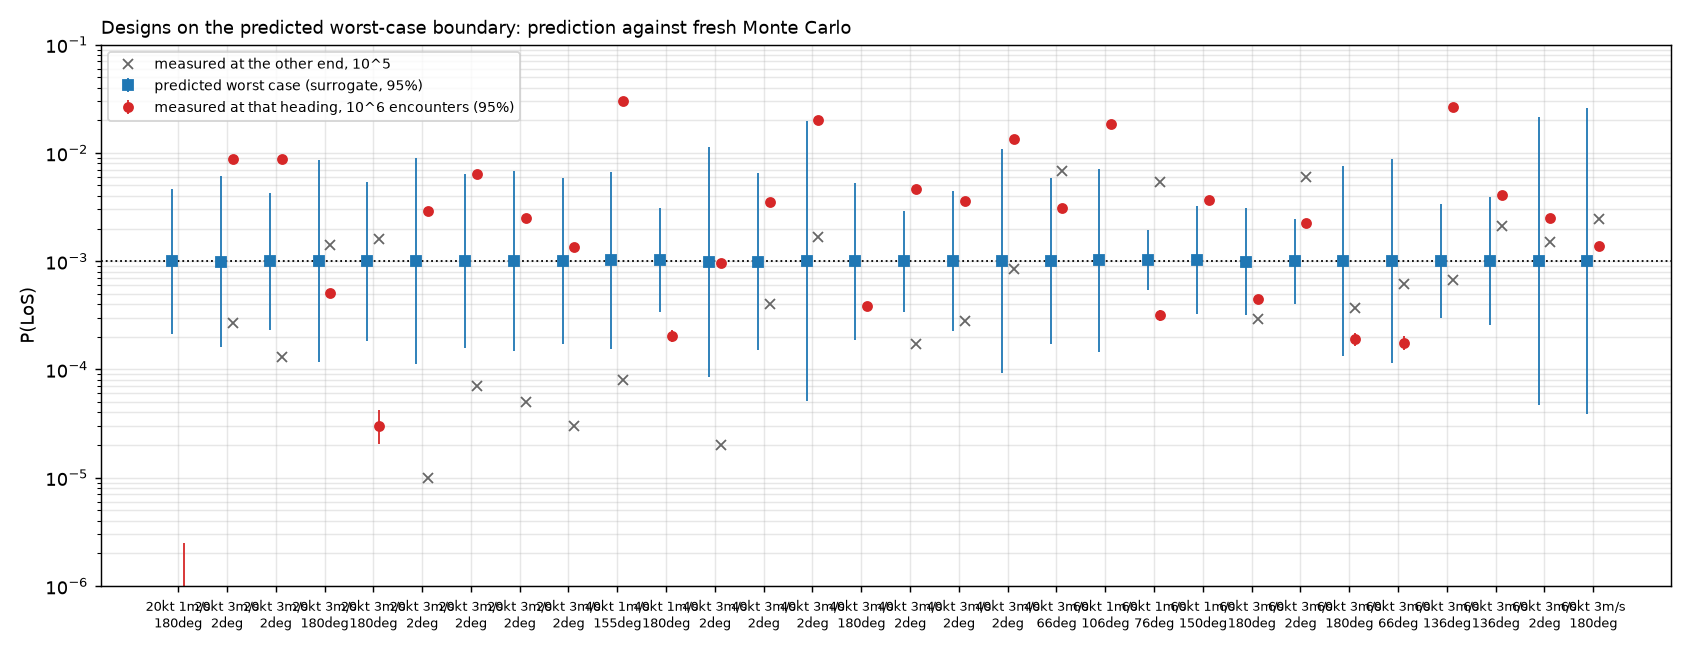

In [9]:
# (b2) Boundary check (notebook 16): designs on the predicted worst-case boundary, 1e6 encounters.
p = Path("results/exp1_boundary_check.csv")
if p.exists() and Path("results/exp1_boundary_check.png").exists():
    bc = pd.read_csv(p)
    display(bc[["speed_kt", "vel", "pos", "p", "R_km", "worst dpsi", "predicted", "measured", "meas 95% lo",
                "meas 95% hi", "predicted acceptable", "measured acceptable", "other end measured"]].round(5))
    display(Image("results/exp1_boundary_check.png", width=900))
else:
    print("notebook 16 has not finished yet")

**What the boundary-check samples change.** The surrogate model is refitted to the 250 campaign samples plus the 60 boundary-check samples (30 at $10^6$ encounters, 30 at $10^5$), with the same settings, and the worst-case requirement is redrawn. The boundary check is then no longer independent of the model, so this figure shows the direction of the correction, not a verified requirement.

The correction concentrates on the shallow-heading boundary at 3 m/s.
- **20 kt:** the acceptable share falls from 0.76–0.81 to 0.56–0.68. A region at reception probability 0.2–0.75 and 6–12 km range becomes unacceptable.
- **40 kt:** from 0.86–0.91 to 0.80–0.83.
- **60 kt:** from 0.87–0.91 to 0.85–0.89.
- **Range floor:** it moves by up to about 1 km in places, in both directions.
- **Unchanged:** 1 m/s (within 0.01), 10 m/s (still nothing acceptable), and the insensitivity to position accuracy.

The reception floor at 3 m/s is therefore the part of the requirement the campaign resolved least well.

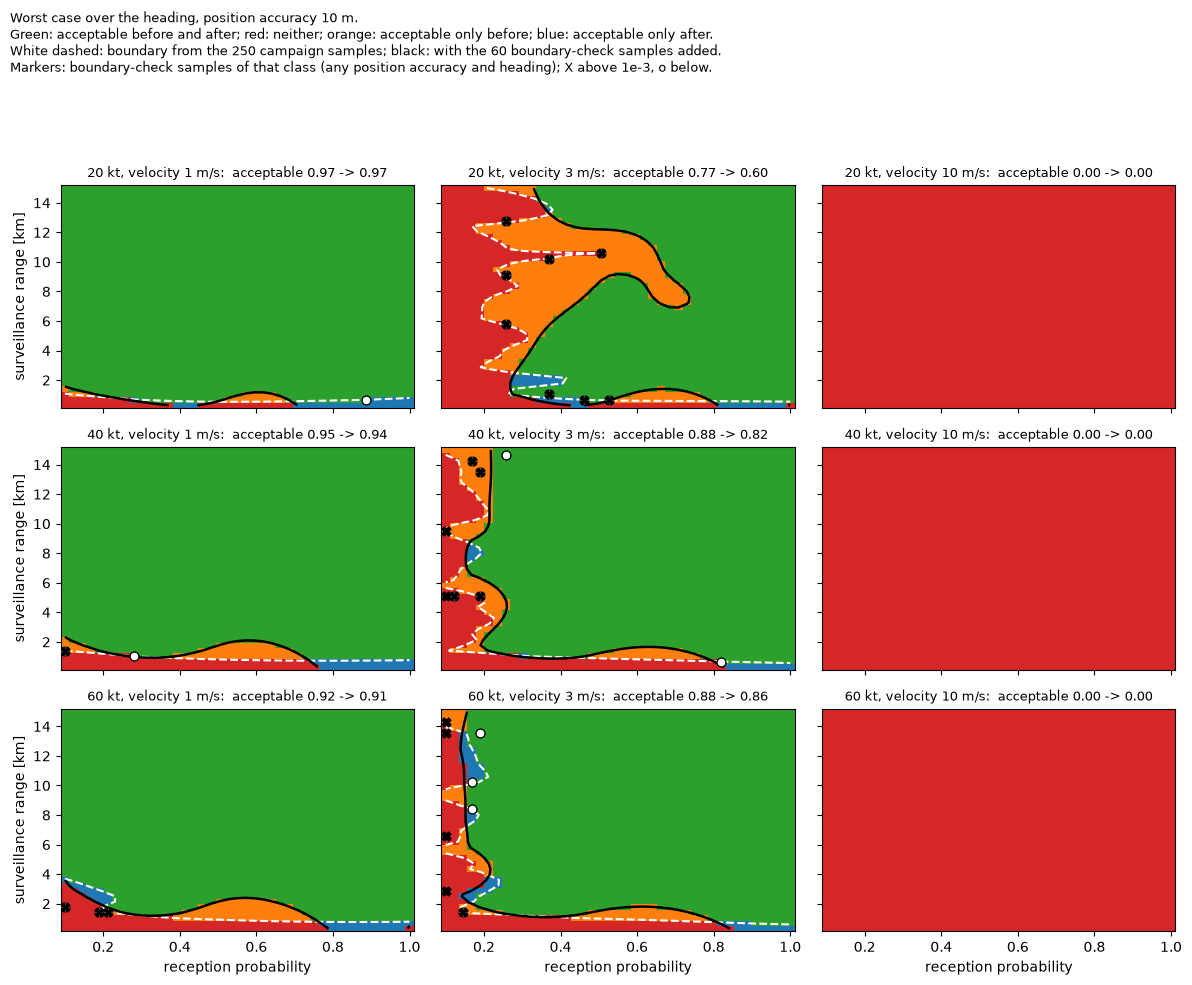

before       after      
                        min   max   min   max
speed velocity [m/s]                         
20 kt 1.0              0.97  0.97  0.97  0.98
      3.0              0.76  0.81  0.56  0.68
      10.0             0.00  0.00  0.00  0.00
40 kt 1.0              0.94  0.95  0.94  0.94
      3.0              0.86  0.91  0.80  0.83
      10.0             0.00  0.00  0.00  0.00
60 kt 1.0              0.92  0.94  0.91  0.92
      3.0              0.87  0.91  0.85  0.89
      10.0             0.00  0.00  0.00  0.00

In [10]:
# Refit with the 60 boundary-check samples added, and compare the worst-case requirement maps.
new = [json.loads(l) for f in ("results/exp1_boundary_worst.jsonl", "results/exp1_boundary_other.jsonl")
       for l in Path(f).read_text().splitlines() if l.strip()]
w_new = space.encode([r["point"] for r in new])
y_new = np.array([r["y"] for r in new])
model2 = fit_surrogate(config.LSE["method"], space, np.vstack([w, w_new]), np.append(y, y_new),
                       correlation=config.LSE["correlation"], rng=np.random.default_rng(config.SEED), n_starts=12)
MU2 = {}
for cat in space.categories:
    m, _ = model2.predict(np.column_stack([G, np.tile(np.array(cat, float), (len(G), 1))]))
    MU2[cat] = m.reshape(N_P, N_R, N_PSI)

# 0 unacceptable in both, 1 became unacceptable, 2 became acceptable, 3 acceptable in both
FOUR = ListedColormap(["tab:red", "tab:orange", "tab:blue", "tab:green"])
POS = 1
pts = pd.DataFrame([r["point"] for r in new]).assign(y=y_new)
fig, axes = plt.subplots(3, 3, figsize=(12, 10), sharex=True, sharey=True)
for k, spd in enumerate(levels["speed"]):
    for j, vel in enumerate(levels["vel_ci95"]):
        ax = axes[k, j]
        before = MU[POS, j, k].max(-1) <= TAU
        after = MU2[POS, j, k].max(-1) <= TAU
        code_ = np.where(before & after, 3, np.where(~before & ~after, 0, np.where(before, 1, 2)))
        ax.pcolormesh(PR, RR, code_, cmap=FOUR, vmin=-0.5, vmax=3.5, shading="auto")
        ax.contour(PR, RR, MU[POS, j, k].max(-1), levels=[TAU], colors="white", linewidths=1.5, linestyles="--")
        ax.contour(PR, RR, MU2[POS, j, k].max(-1), levels=[TAU], colors="black", linewidths=1.8, linestyles="solid")
        sel = (np.isclose(pts.speed, spd)) & (pts.vel_ci95 == vel)
        for bad, mk in ((False, "o"), (True, "X")):
            s_ = sel & ((pts.y > TAU) == bad)
            ax.scatter(pts.p_reception[s_], pts.max_range_m[s_] / 1e3, marker=mk, s=40,
                       c="white" if not bad else "black", edgecolors="black", linewidths=0.8, zorder=3)
        ax.set_title(f"{kt(spd)}, velocity {vel:g} m/s:  acceptable {before.mean():.2f} -> {after.mean():.2f}", fontsize=9)
        if k == 2: ax.set_xlabel("reception probability")
        if j == 0: ax.set_ylabel("surveillance range [km]")
fig.suptitle("Worst case over the heading, position accuracy 10 m.\n"
             "Green: acceptable before and after; red: neither; orange: acceptable only before; blue: acceptable only after.\n"
             "White dashed: boundary from the 250 campaign samples; black: with the 60 boundary-check samples added.\n"
             "Markers: boundary-check samples of that class (any position accuracy and heading); X above 1e-3, o below.",
             x=0.01, ha="left", fontsize=9)
plt.tight_layout(rect=(0, 0, 1, 0.92)); plt.savefig("results/R_requirement_maps_with_check.png", dpi=130); plt.show()

rows = []
for (ipos, ivel, k), mu in MU.items():
    rows.append({"speed": kt(levels["speed"][k]), "velocity [m/s]": levels["vel_ci95"][ivel],
                 "before": np.mean(mu.max(-1) <= TAU), "after": np.mean(MU2[ipos, ivel, k].max(-1) <= TAU)})
display(pd.DataFrame(rows).groupby(["speed", "velocity [m/s]"])[["before", "after"]].agg(["min", "max"]).round(2))

**What passing the standard error would change.** The surrogate model is refitted to the same 250 campaign samples, now with each sample's Monte Carlo standard error as known observation noise: $s_{MC}^2$ is added to the diagonal of the correlation matrix, and the delta-method value on the log scale gives about 0.6 decades for a sample with no LoS. Nothing else changes. The boundary-check samples are not used, so they still test both models independently.

**Passing the standard error barely changes the requirement.** The prediction-based acceptable shares move by at most 0.02, and both boundaries lie within the same band at 3 m/s. The boundary error of Section 5.6 (b2) is therefore not caused by treating the responses as exact.
- **Standard error near $10^{-3}$:** 0.046 decades, a small fraction of the factor-of-4 error at the boundary.
- **Boundary check:** both models fail it alike, with a median error of a factor of 3.8 (exact) and 4.1 (with the standard error), and 60% of designs on the correct side for both.

**What changes is the conservative reading.** With the standard error, the re-estimated hyperparameters give a smaller modelling uncertainty, so the share acceptable at the prediction + 1.96 s rises, for example from 0.05–0.13 to 0.12–0.51 at 20 kt and 3 m/s.

That narrower interval is less honest on the boundary: it contains the measured value at 37% of the boundary-check designs, against 50% without the standard error. Treating the responses as exact is thus the more cautious choice here.

standard error per sample: median 0.04 decades; near 1e-3: 0.046; no LoS: 0.61


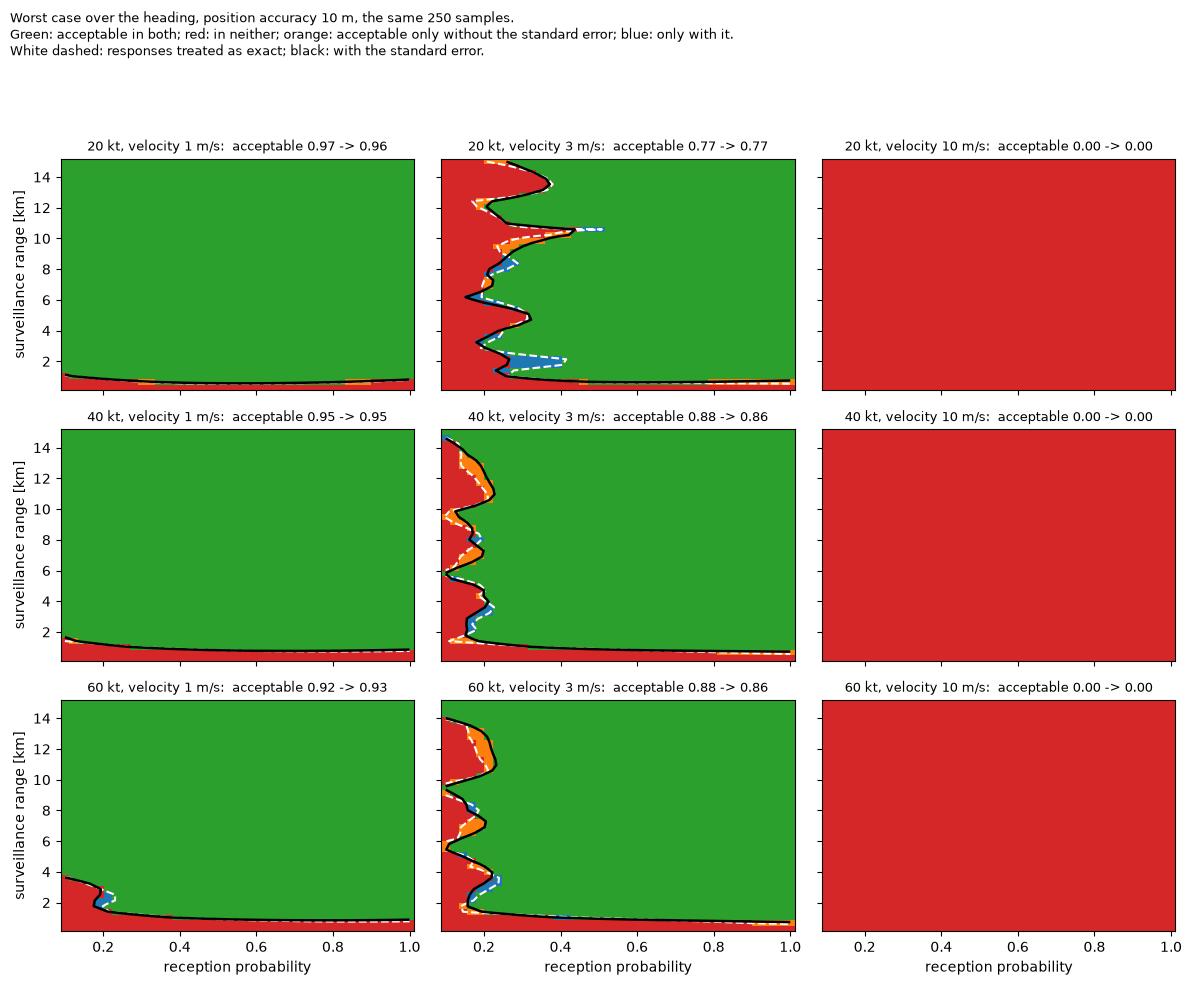

exact       with se       exact, + 1.96 s        \
                       min   max     min   max             min   max   
speed velocity [m/s]                                                   
20 kt 1.0             0.97  0.97    0.95  0.96            0.22  0.43   
      3.0             0.76  0.81    0.75  0.80            0.05  0.13   
      10.0            0.00  0.00    0.00  0.00            0.00  0.00   
40 kt 1.0             0.94  0.95    0.94  0.95            0.42  0.61   
      3.0             0.86  0.91    0.85  0.89            0.30  0.47   
      10.0            0.00  0.00    0.00  0.00            0.00  0.00   
60 kt 1.0             0.92  0.94    0.93  0.94            0.34  0.48   
      3.0             0.87  0.91    0.85  0.89            0.26  0.42   
      10.0            0.00  0.00    0.00  0.00            0.00  0.00   

                     with se, + 1.96 s        
                                   min   max  
speed velocity [m/s]                          
20 kt 1.0                         0.37  0.71  
      3.0                         0.12  0.51  
      10.0                        0.00  0.00  
40 kt 1.0                         0.63  0.87  
      3.0                         0.45  0.78  
      10.0                        0.00  0.00  
60 kt 1.0                         0.52  0.78  
      3.0                         0.40  0.74  
      10.0                        0.00  0.00

,exact,with se
median |error| [factor],3.84,4.13
side of 1e-3 correct,0.60,0.60
inside 95% interval,0.50,0.37
"predicted acceptable, measured not",10.00,8.00


In [11]:
# Same 250 samples, with and without the Monte Carlo standard error of each response.
p_hat = 10 ** y
se_mc = np.sqrt((1.0 - p_hat) / (N * p_hat)) / np.log(10.0)          # delta method, as blueskycdarr reports it
model_se = fit_surrogate(config.LSE["method"], space, w, y, se_mc, correlation=config.LSE["correlation"],
                         rng=np.random.default_rng(config.SEED), n_starts=12)
MU3, S3 = {}, {}
for cat in space.categories:
    m, s = model_se.predict(np.column_stack([G, np.tile(np.array(cat, float), (len(G), 1))]))
    MU3[cat], S3[cat] = m.reshape(N_P, N_R, N_PSI), s.reshape(N_P, N_R, N_PSI)
print(f"standard error per sample: median {np.median(se_mc):.2f} decades; near 1e-3: "
      f"{np.median(se_mc[np.abs(y - TAU) < 0.5]):.3f}; no LoS: {se_mc[y <= np.log10(0.5 / (N + 1)) + 1e-9].mean():.2f}")

fig, axes = plt.subplots(3, 3, figsize=(12, 10), sharex=True, sharey=True)
for k, spd in enumerate(levels["speed"]):
    for j, vel in enumerate(levels["vel_ci95"]):
        ax = axes[k, j]
        before = MU[POS, j, k].max(-1) <= TAU
        after = MU3[POS, j, k].max(-1) <= TAU
        code_ = np.where(before & after, 3, np.where(~before & ~after, 0, np.where(before, 1, 2)))
        ax.pcolormesh(PR, RR, code_, cmap=FOUR, vmin=-0.5, vmax=3.5, shading="auto")
        ax.contour(PR, RR, MU[POS, j, k].max(-1), levels=[TAU], colors="white", linewidths=1.5, linestyles="dashed")
        ax.contour(PR, RR, MU3[POS, j, k].max(-1), levels=[TAU], colors="black", linewidths=1.8, linestyles="solid")
        ax.set_title(f"{kt(spd)}, velocity {vel:g} m/s:  acceptable {before.mean():.2f} -> {after.mean():.2f}", fontsize=9)
        if k == 2: ax.set_xlabel("reception probability")
        if j == 0: ax.set_ylabel("surveillance range [km]")
fig.suptitle("Worst case over the heading, position accuracy 10 m, the same 250 samples.\n"
             "Green: acceptable in both; red: in neither; orange: acceptable only without the standard error; "
             "blue: only with it.\nWhite dashed: responses treated as exact; black: with the standard error.",
             x=0.01, ha="left", fontsize=9)
plt.tight_layout(rect=(0, 0, 1, 0.93)); plt.savefig("results/R_requirement_maps_se.png", dpi=130); plt.show()

rows = []
for (ipos, ivel, k), mu in MU.items():
    rows.append({"speed": kt(levels["speed"][k]), "velocity [m/s]": levels["vel_ci95"][ivel],
                 "exact": np.mean(mu.max(-1) <= TAU), "with se": np.mean(MU3[ipos, ivel, k].max(-1) <= TAU),
                 "exact, + 1.96 s": np.mean((mu + 1.96 * S[ipos, ivel, k]).max(-1) <= TAU),
                 "with se, + 1.96 s": np.mean((MU3[ipos, ivel, k] + 1.96 * S3[ipos, ivel, k]).max(-1) <= TAU)})
display(pd.DataFrame(rows).groupby(["speed", "velocity [m/s]"]).agg(["min", "max"]).round(2))

# Both models against the boundary check (independent of both): predicted worst case over the heading at each
# of the 30 designs, against the worse of the two measured ends.
bc = pd.read_csv("results/exp1_boundary_check.csv")
worst_pts = [json.loads(l)["point"] for l in Path("results/exp1_boundary_worst.jsonl").read_text().splitlines() if l.strip()]
wd = space.encode(worst_pts)
meas = np.log10(np.maximum(bc.measured, bc["other end measured"]).clip(lower=1e-7))
out = {}
for name, m in (("exact", model), ("with se", model_se)):
    pred = np.max([m.predict(np.column_stack([wd[:, :2], np.full(len(wd), u), wd[:, 3:]]))[0] for u in su], axis=0)
    mu_s = [m.predict(np.column_stack([wd[:, :2], np.full(len(wd), u), wd[:, 3:]])) for u in su]
    iw = np.argmax([a for a, _ in mu_s], axis=0)
    sd = np.array([mu_s[i][1][d] for d, i in enumerate(iw)])
    out[name] = {"median |error| [factor]": 10 ** np.median(np.abs(meas - pred)),
                 "side of 1e-3 correct": np.mean((pred <= TAU) == (meas <= TAU)),
                 "inside 95% interval": np.mean(np.abs(meas - pred) <= 1.96 * sd),
                 "predicted acceptable, measured not": int(np.sum((pred <= TAU) & (meas > TAU)))}
pd.DataFrame(out).round(2)

## Pending

- **Exp. 2:** surfaces at 2° and 180° for 20 kt. Not run, so the requirement table and the trade-off curves of the outline are not available. Section 5.3 reads them from Exp. 1 instead.
- **Exp. 3:** the mechanism check of the resolution margin. Not run.
- **5.6:** the second-engine check. Not run.
- **Outline correction:** the outline in `05ExperimentsResults.tex` expects a non-monotone correlation structure for *position* accuracy. Exp. 1 shows it for *velocity* accuracy instead, with position levels correlated at 0.89–0.99.